#### This is a dataset consisting of restaurant reviews. Your goal is to predict the `stars` column.
Adapted from Katie Sylvia

#### Imports

In [363]:
import numpy as np
import pandas as pd       
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

import nltk
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [364]:
df = pd.read_csv('data/restaurant_reviews.csv', index_col = 0)

In [365]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   stars   10000 non-null  int64 
 1   text    10000 non-null  object
dtypes: int64(1), object(1)
memory usage: 234.4+ KB


In [366]:
df = df.sample(5000, random_state=404)

#### Check baseline

In [367]:
df['stars'].value_counts(normalize=True)

stars
5    0.361
4    0.332
3    0.150
2    0.089
1    0.068
Name: proportion, dtype: float64

In [368]:
df['stars'] = df['stars'].map({1:'1 star', 2:'2 stars', 3:'3 stars', 4:'4 stars', 5:'5 stars'})

#### Sentiment analysis

In [369]:
# Initialize VADER
analyzer = SentimentIntensityAnalyzer()

def get_sentiment_score(sentence):
    scores = analyzer.polarity_scores(sentence)
    return scores['compound']  # Compound score is a normalized score [-1, 1]

get_sentiment_score("I love food!"), get_sentiment_score("I hate food!"), get_sentiment_score("food is okay")

(0.6696, -0.6114, 0.2263)

What if I wanted to include the sentiment score as a feature in my model?

In [370]:
df['nltk_sentiment'] = df['text'].apply(lambda x:get_sentiment_score(x))
df['nltk_sentiment'].head()

1860    0.9371
4182    0.9545
8726    0.9544
1892    0.6934
8044    0.9983
Name: nltk_sentiment, dtype: float64

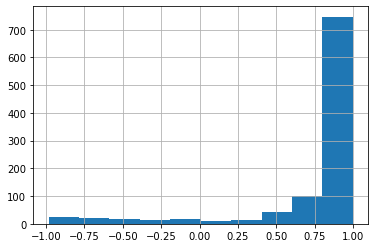

In [371]:
df.nltk_sentiment.hist();

In [388]:
get_sentiment_score("sick burrito! That food was fire")

-0.4389

In [389]:
get_sentiment_score("I got sick! The food was on fire")

-0.4389

In [396]:
analyzer.polarity_scores("sick burrito! That food was fire")

{'neg': 0.387, 'neu': 0.43, 'pos': 0.183, 'compound': -0.4389}

In [397]:
analyzer.polarity_scores("I got sick! The food was on fire")

{'neg': 0.349, 'neu': 0.486, 'pos': 0.165, 'compound': -0.4389}

In [398]:
# Custom sentiment scores?

analyzer.lexicon['fire']# = 0.7

0.7

In [399]:
# pip install -q transformers

from transformers import pipeline
sentiment_pipeline = pipeline("sentiment-analysis")

data = ["Sick burrito! that food was fire", "I got sick! The food was on fire"]
sentiment_pipeline(data)

No model was supplied, defaulted to distilbert-base-uncased-finetuned-sst-2-english (https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-english)


[{'label': 'NEGATIVE', 'score': 0.9960733652114868},
 {'label': 'NEGATIVE', 'score': 0.9924522042274475}]

[huggingface](https://huggingface.co/cardiffnlp/twitter-roberta-base)

In [405]:
# Initialize the sentiment analysis pipeline
sentiment_pipeline = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment")

# Example texts with slang
data = ["Sick burrito! that food was fire", "I got sick! The food was on fire"]

# Perform sentiment analysis
sentiment_pipeline(data)

[{'label': 'LABEL_2', 'score': 0.7672207355499268},
 {'label': 'LABEL_0', 'score': 0.968166172504425}]

In [437]:
from transformers import pipeline, AutoModelForSequenceClassification, AutoTokenizer

model_name = "finiteautomata/bertweet-base-sentiment-analysis"
model = AutoModelForSequenceClassification.from_pretrained(model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Sentiment analysis pipeline with specified model and tokenizer
analyzer = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

# Example texts
texts = ["I got sick! the food was on fire", "my burrito was sick! the food was fire"]

# Perform sentiment analysis
results = analyzer(texts)

# Display results
for text, result in zip(texts, results):
    print(f"Text: {text}")
    print(f"Sentiment: {result['label']}, Score: {result['score']:.4f}")

emoji is not installed, thus not converting emoticons or emojis into text. Install emoji: pip3 install emoji==0.6.0


Text: I got sick! the food was on fire
Sentiment: NEG, Score: 0.9801
Text: my burrito was sick! the food was fire
Sentiment: POS, Score: 0.6291


#### Train Test Split

In [408]:
X = df[['text', 'nltk_sentiment']]
y = df['stars']

In [409]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=123)

In [410]:
X_train

,text,nltk_sentiment
7642,Wound up at Rock Bottom by chance had been wan...,0.9361
1541,"I had a good time at Monkey Pants, we celebrat...",0.8979
378,Good destination for pizza. Would frequently g...,0.6908
4675,"I love their wheat bread, and I love that I c...",0.9722
7541,"Ok here is the deal, I am sad to only give gro...",0.6006
...,...,...
2104,I liked the fish. It was delicious. The cole...,0.6966
6778,"Ok, I have been coming to Wong's Place for a n...",0.9968
1286,"Love the Vig Uptown's vibe, decor and oh yeah,...",0.8724
8435,I feel like an East Coast gangster when I roll...,0.9678


#### Pipeline

In [411]:
preprocessor = ColumnTransformer(
    transformers=[
        ('text_vectorizer', CountVectorizer(stop_words='english'), 'text')  # CountVectorizer for text column
    ],
    remainder='passthrough'
)

# max_df=.8, min_df=.1

In [412]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('logreg', LogisticRegression(max_iter=1000))  # Remember, default is l2
])

In [413]:
pipe.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('text_vectorizer',
                                                  CountVectorizer(stop_words='english'),
                                                  'text')])),
                ('logreg', LogisticRegression(max_iter=1000))])

My `text` column was passed through my preprocessor, and my `sentiment` column was passed through unaltered as the remainder. 

#### Score on training and testing set

In [414]:
pipe.score(X_train, y_train), pipe.score(X_test, y_test)

(0.9986666666666667, 0.472)

It looks a little overfit! We could try reducing dimensionality:

- max_features
- min_df
- max_df

In [415]:
# What is "class 1"? Classes in logistic regression are assigned based on the unique values present in the target column. Be careful.

y.unique()

array(['3 stars', '4 stars', '1 star', '5 stars', '2 stars'], dtype=object)

In [416]:
labels = ['3 stars', '4 stars', '1 star', '5 stars', '2 stars']

# Generate predictions on the test set
y_pred = pipe.predict(X_test)

# Compute classification report
report = classification_report(y_test, y_pred, labels = labels)

# Print the report
print(report)

              precision    recall  f1-score   support

     3 stars       0.24      0.28      0.26        32
     4 stars       0.54      0.47      0.51        91
      1 star       0.43      0.14      0.21        21
     5 stars       0.51      0.69      0.59        86
     2 stars       0.36      0.20      0.26        20

    accuracy                           0.47       250
   macro avg       0.42      0.36      0.36       250
weighted avg       0.47      0.47      0.46       250



In [417]:
# talk about OvR

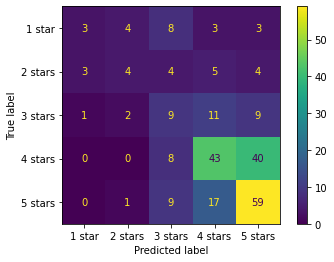

In [418]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test);

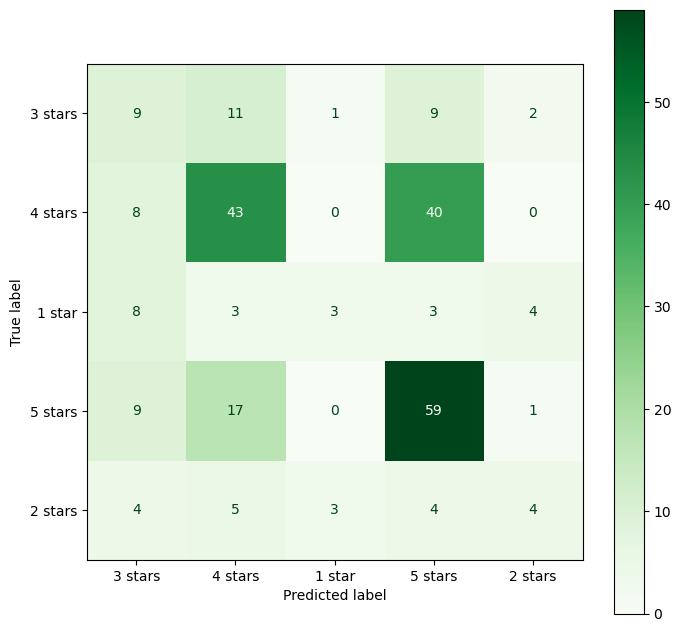

In [419]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=100)
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, cmap='Greens', labels=labels, ax=ax, text_kw={'fontsize': 10});

#### One more...

In [420]:
preprocessor = ColumnTransformer(
    transformers=[
        ('text_vectorizer', CountVectorizer(), 'text'), 
    ],
    remainder='passthrough'
)

In [421]:
pipe2 = Pipeline([
    ('preprocessor', preprocessor), 
    ('logreg', LogisticRegression(max_iter=1000, penalty='l1', C=0.1, solver='saga'))
])

pipe2.fit(X_train, y_train)
pipe2.score(X_train, y_train), pipe2.score(X_test, y_test)

(0.5413333333333333, 0.456)

Slightly less overfit.

In [426]:
from sklearn.metrics import classification_report

labels = ['3 stars', '4 stars', '1 star', '5 stars', '2 stars']
y_pred = pipe2.predict(X_test)
report = classification_report(y_test, y_pred, labels = labels)
print(report)

              precision    recall  f1-score   support

     3 stars       0.00      0.00      0.00        32
     4 stars       0.43      0.38      0.40        91
      1 star       0.71      0.24      0.36        21
     5 stars       0.49      0.80      0.61        86
     2 stars       0.28      0.25      0.26        20

    accuracy                           0.46       250
   macro avg       0.38      0.34      0.33       250
weighted avg       0.41      0.46      0.41       250



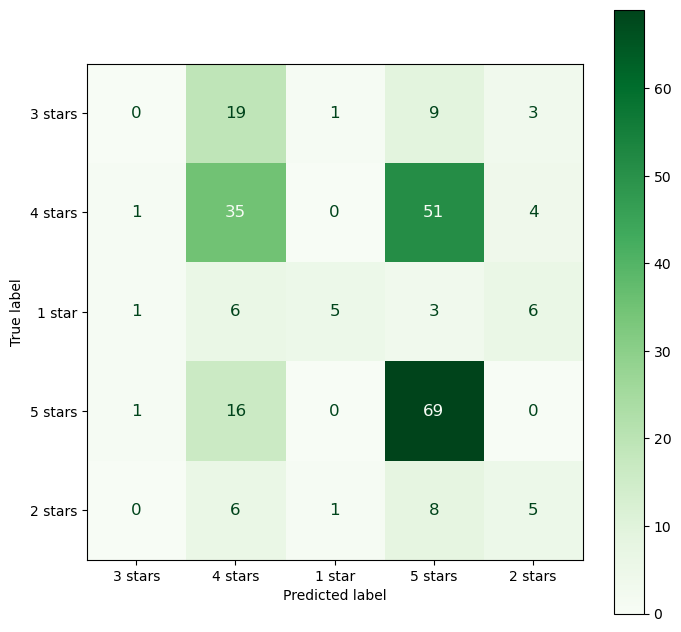

In [427]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=100)
ConfusionMatrixDisplay.from_estimator(pipe2, X_test, y_test, cmap = 'Greens', labels = labels, ax=ax, text_kw={'fontsize': 12});

#### Feature importances

In [428]:
# Column names
words = pipe2.named_steps['preprocessor'].named_transformers_['text_vectorizer'].get_feature_names_out()

# Coefs
coefs = pipe2.named_steps['logreg'].coef_
coefs 

# Why do I have 5 lists of coefs? Because I have 5 classes.

array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        , -0.88752328],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        , -0.92885374],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.7439413 ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  1.10275543]])

In [429]:
coefs[3] # 5 star reviews

# add sentiment score to my array of features
words = np.append(words, 'sentiment score')

In [430]:
# Most predictive of 5 star review

pd.DataFrame(coefs[3], index=words).sort_values(by=0, ascending = False)

,0
sentiment score,0.743941
little,0.274756
some,0.184946
menu,0.145823
chicken,0.141237
...,...
so,-0.076990
our,-0.089515
what,-0.094842
going,-0.131017


In [431]:
# Most predictive of 1 star review

pd.DataFrame(coefs[2], index=words).sort_values(by=0, ascending = False)

,0
but,0.135177
good,0.125138
lunch,0.097517
it,0.087808
people,0.077518
...,...
feast,0.000000
sentiment score,0.000000
and,-0.031915
my,-0.049196


You can't interpret these like regular coefs! Instead you can talk about relative importance.

In [432]:
# What if I want to aggregate my predictions from multiple models?

from sklearn.ensemble import VotingClassifier
voting_clf = VotingClassifier(estimators=[('pipe', pipe), ('pipe2', pipe2)], voting='soft')

voting_clf.fit(X_train, y_train)
y_pred = voting_clf.predict(X_test)

report = classification_report(y_test, y_pred, labels=labels)
print(report)

# 'hard' for majority voting, 'soft' for averaging predicted probabilities.

              precision    recall  f1-score   support

     3 stars       0.30      0.25      0.27        32
     4 stars       0.55      0.49      0.52        91
      1 star       0.57      0.19      0.29        21
     5 stars       0.53      0.72      0.61        86
     2 stars       0.41      0.35      0.38        20

    accuracy                           0.50       250
   macro avg       0.47      0.40      0.41       250
weighted avg       0.50      0.50      0.49       250



#### Next steps...
- Gridsearch
- Text preprocessing functions
- Try new models (coming soon!)